# Vision — Konversi Format Anotasi (YOLO, COCO, VOC, mask, polygon, RLE)
**Kapan dipakai:** format anotasi dari soal berbeda dengan format yang diminta model atau file
kiriman.

**Langkah:** semua kotak disimpan di satu **tabel piksel** (gambar, kelas, x1, y1, x2, y2).
Tiap format cukup punya dua sel: "tabel → format" dan "format → tabel", dan tiap konversi dicek
bolak-balik. Ada juga cek anotasi rusak dan overlay visual.

**Data demo:** coco8 (kotak, format YOLO) dan satu mask PennFudanPed (mask, polygon, RLE).

In [1]:
import glob
import json
import os
import xml.etree.ElementTree as ET

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/detection/coco8"   # GANTI saat lomba
IMAGE_FOLDER = f"{DATA_FOLDER}/images/train"
LABEL_FOLDER = f"{DATA_FOLDER}/labels/train"
IMAGE_EXTENSION = ".jpg"
PENNFUDAN_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/detection/PennFudanPed"
MASK_FILE = f"{PENNFUDAN_FOLDER}/PedMasks/FudanPed00001_mask.png"
MASK_IMAGE_FILE = f"{PENNFUDAN_FOLDER}/PNGImages/FudanPed00001.png"
YOLO_WEIGHTS = "Z:/GEMASTIK-DATABASE/pretrained/yolov8n/yolov8n.pt"
VOC_FOLDER = "voc"                 # hasil konversi (di folder notebook)
YOLO_BACK_FOLDER = "yolo_kembali"

COORDINATES = ["x1", "y1", "x2", "y2"]
CLASS_NAMES = YOLO(YOLO_WEIGHTS).names     # {id kelas: nama}, 80 kelas COCO

## Baca YOLO → tabel piksel (format pusat untuk semua konversi)
Baris YOLO: `kelas cx cy w h`, semua 0–1 relatif ukuran gambar.

In [3]:
image_paths = sorted(glob.glob(f"{IMAGE_FOLDER}/*{IMAGE_EXTENSION}"))
image_names = []
image_sizes = {}
for image_path in image_paths:
    name = os.path.basename(image_path)
    image_names.append(name)
    image_sizes[name] = Image.open(image_path).size      # (lebar, tinggi)

rows = []
for name in image_names:
    width, height = image_sizes[name]
    stem = os.path.splitext(name)[0]
    for line in open(f"{LABEL_FOLDER}/{stem}.txt").read().splitlines():
        class_id, cx, cy, box_width, box_height = line.split()
        cx = float(cx) * width
        cy = float(cy) * height
        box_width = float(box_width) * width
        box_height = float(box_height) * height
        rows.append([name, width, height, int(class_id), cx - box_width / 2,
                     cy - box_height / 2, cx + box_width / 2, cy + box_height / 2])

boxes = pd.DataFrame(rows, columns=["image", "width", "height", "class_id",
                                    "x1", "y1", "x2", "y2"])
print(boxes.shape)
boxes.head()

(13, 8)


,image,width,height,class_id,x1,y1,x2,y2
0,000000000009.jpg,640,480,45,1.08000,187.69008,612.66976,473.53008
1,000000000009.jpg,640,480,45,311.73024,4.31016,631.01024,232.99032
2,000000000009.jpg,640,480,50,249.60032,229.27032,565.84032,474.35016
3,000000000009.jpg,640,480,45,0.00032,13.51008,434.48032,388.63008
4,000000000009.jpg,640,480,49,376.20000,40.35996,451.75008,86.88996


## Cek anotasi rusak
Dicoba di data asli, lalu di salinan yang sengaja dirusak.

In [4]:
def find_problems(table):
    area = (table["x2"] - table["x1"]) * (table["y2"] - table["y1"])
    outside = (table["x1"] < -0.5) | (table["y1"] < -0.5)
    outside = outside | (table["x2"] > table["width"] + 0.5)
    outside = outside | (table["y2"] > table["height"] + 0.5)
    known_class = table["class_id"].isin(list(CLASS_NAMES))
    problems = []
    for image, is_outside, box_area, is_known in zip(table["image"], outside, area, known_class):
        if is_outside:
            problems.append((image, "koordinat di luar gambar"))
        if box_area <= 0:
            problems.append((image, "luas kotak nol"))
        if not is_known:
            problems.append((image, "kelas tak dikenal"))
    labeled_images = set(table["image"])
    for name in image_names:
        if name not in labeled_images:
            problems.append((name, "gambar tanpa label"))
    return pd.DataFrame(problems, columns=["image", "kind"])


print("data asli, jumlah masalah:", len(find_problems(boxes)))
broken = boxes.copy()
broken.loc[0, "x2"] = broken.loc[0, "width"] + 50      # keluar gambar
broken.loc[1, "x2"] = broken.loc[1, "x1"]              # luas nol
broken.loc[2, "class_id"] = 99                          # kelas tak dikenal
broken = broken[broken["image"] != image_names[-1]]    # gambar terakhir kehilangan label
find_problems(broken)

data asli, jumlah masalah: 0


,image,kind
0,000000000009.jpg,koordinat di luar gambar
1,000000000009.jpg,luas kotak nol
2,000000000009.jpg,kelas tak dikenal
3,000000000034.jpg,gambar tanpa label


## Tabel → COCO JSON
COCO: `bbox = [kiri, atas, lebar, tinggi]` piksel, `category_id` mulai dari 1 (YOLO mulai 0).

In [5]:
coco = {"images": [], "annotations": [], "categories": []}
for class_id in CLASS_NAMES:
    coco["categories"].append({"id": class_id + 1, "name": CLASS_NAMES[class_id]})
for number, name in enumerate(image_names):
    width, height = image_sizes[name]
    coco["images"].append({"id": number + 1, "file_name": name, "width": width, "height": height})
for number, box in enumerate(boxes.itertuples()):
    box_width = box.x2 - box.x1
    box_height = box.y2 - box.y1
    coco["annotations"].append({
        "id": number + 1,
        "image_id": image_names.index(box.image) + 1,
        "category_id": box.class_id + 1,
        "bbox": [box.x1, box.y1, box_width, box_height],
        "area": box_width * box_height,
        "iscrowd": 0,
    })
with open("anotasi_coco.json", "w") as file:
    json.dump(coco, file)
print("COCO:", len(coco["images"]), "gambar,", len(coco["annotations"]), "anotasi")

COCO: 4 gambar, 13 anotasi


## COCO JSON → tabel (dicek sama dengan tabel awal)

In [6]:
with open("anotasi_coco.json") as file:
    coco = json.load(file)
image_info = {}
for item in coco["images"]:
    image_info[item["id"]] = item

rows = []
for annotation in coco["annotations"]:
    info = image_info[annotation["image_id"]]
    left, top, box_width, box_height = annotation["bbox"]
    rows.append([info["file_name"], info["width"], info["height"], annotation["category_id"] - 1,
                 left, top, left + box_width, top + box_height])
from_coco = pd.DataFrame(rows, columns=boxes.columns)
difference = (from_coco[COORDINATES] - boxes[COORDINATES]).abs()
print("selisih terbesar:", difference.max().max())

selisih terbesar: 0.0


## Tabel → Pascal VOC XML (satu file per gambar, koordinat bilangan bulat)

In [7]:
os.makedirs(VOC_FOLDER, exist_ok=True)
for name in image_names:
    width, height = image_sizes[name]
    root = ET.Element("annotation")
    ET.SubElement(root, "filename").text = name
    size = ET.SubElement(root, "size")
    ET.SubElement(size, "width").text = str(width)
    ET.SubElement(size, "height").text = str(height)
    ET.SubElement(size, "depth").text = "3"
    for box in boxes[boxes["image"] == name].itertuples():
        item = ET.SubElement(root, "object")
        ET.SubElement(item, "name").text = CLASS_NAMES[box.class_id]
        bndbox = ET.SubElement(item, "bndbox")
        ET.SubElement(bndbox, "xmin").text = str(round(box.x1))
        ET.SubElement(bndbox, "ymin").text = str(round(box.y1))
        ET.SubElement(bndbox, "xmax").text = str(round(box.x2))
        ET.SubElement(bndbox, "ymax").text = str(round(box.y2))
    stem = os.path.splitext(name)[0]
    ET.ElementTree(root).write(f"{VOC_FOLDER}/{stem}.xml")
print("file VOC:", len(glob.glob(f"{VOC_FOLDER}/*.xml")))

file VOC: 4


## Pascal VOC XML → tabel

In [8]:
class_ids = {}       # nama kelas -> id kelas
for class_id in CLASS_NAMES:
    class_ids[CLASS_NAMES[class_id]] = class_id

rows = []
for xml_file in sorted(glob.glob(f"{VOC_FOLDER}/*.xml")):
    root = ET.parse(xml_file).getroot()
    width = int(root.find("size/width").text)
    height = int(root.find("size/height").text)
    for item in root.findall("object"):
        x1 = float(item.find("bndbox/xmin").text)
        y1 = float(item.find("bndbox/ymin").text)
        x2 = float(item.find("bndbox/xmax").text)
        y2 = float(item.find("bndbox/ymax").text)
        class_id = class_ids[item.find("name").text]
        rows.append([root.find("filename").text, width, height, class_id, x1, y1, x2, y2])
from_voc = pd.DataFrame(rows, columns=boxes.columns)
difference = (from_voc[COORDINATES] - boxes[COORDINATES]).abs()
print("jumlah kotak:", len(from_voc))
print("selisih piksel terbesar (karena dibulatkan):", difference.max().max())

jumlah kotak: 13
selisih piksel terbesar (karena dibulatkan): 0.4998399999999492


## Tabel → YOLO (balik ke format awal, dibandingkan dengan file asli)

In [9]:
os.makedirs(YOLO_BACK_FOLDER, exist_ok=True)
for name in image_names:
    lines = []
    for box in boxes[boxes["image"] == name].itertuples():
        cx = (box.x1 + box.x2) / 2 / box.width
        cy = (box.y1 + box.y2) / 2 / box.height
        box_width = (box.x2 - box.x1) / box.width
        box_height = (box.y2 - box.y1) / box.height
        lines.append(f"{box.class_id} {cx:.6f} {cy:.6f} {box_width:.6f} {box_height:.6f}")
    stem = os.path.splitext(name)[0]
    with open(f"{YOLO_BACK_FOLDER}/{stem}.txt", "w") as file:
        file.write("\n".join(lines))

first_stem = os.path.splitext(image_names[0])[0]
original = np.array(open(f"{LABEL_FOLDER}/{first_stem}.txt").read().split(), dtype=float)
back = np.array(open(f"{YOLO_BACK_FOLDER}/{first_stem}.txt").read().split(), dtype=float)
print("selisih terbesar:", np.abs(original - back).max())

selisih terbesar: 5.000000000005e-07


## Mask biner → polygon (cv2.findContours) → mask lagi, serta baris YOLO-seg

In [10]:
person_ids = np.array(Image.open(MASK_FILE))     # tiap piksel = nomor orang (0 = latar)
mask = (person_ids == 1).astype(np.uint8)
height, width = mask.shape
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
largest = contours[0]
for contour in contours:
    if cv2.contourArea(contour) > cv2.contourArea(largest):
        largest = contour
polygon = largest.reshape(-1, 2)      # daftar titik (x, y)

mask_back = np.zeros_like(mask)
cv2.fillPoly(mask_back, [polygon], 1)
print("titik polygon:", len(polygon))
print("IoU mask asli vs hasil polygon:", (mask & mask_back).sum() / (mask | mask_back).sum())

yolo_seg = "0"       # kelas, lalu x y x y ... relatif ukuran gambar
for point_x, point_y in polygon:
    yolo_seg = yolo_seg + f" {point_x / width:.6f} {point_y / height:.6f}"
print("baris YOLO-seg:", yolo_seg[:80], "...")
coco_polygon = [polygon.flatten().tolist()]   # format "segmentation" di COCO

titik polygon: 410
IoU mask asli vs hasil polygon: 0.9999110478562533
baris YOLO-seg: 0 0.406082 0.337687 0.393560 0.350746 0.393560 0.352612 0.388193 0.358209 0.3881 ...


## Mask ↔ RLE gaya Kaggle
Piksel dibaca per kolom (atas ke bawah, lalu kolom berikutnya). Isi: `awal panjang awal panjang
...`, nomor piksel mulai dari 1.

In [11]:
def mask_to_rle(mask):
    bits = np.concatenate([[0], mask.flatten(order="F"), [0]])
    edges = np.where(bits[1:] != bits[:-1])[0] + 1     # posisi piksel berubah 0↔1
    edges[1::2] = edges[1::2] - edges[::2]             # posisi akhir → panjang
    numbers = []
    for edge in edges:
        numbers.append(str(edge))
    return " ".join(numbers)


def rle_to_mask(rle, height, width):
    numbers = np.array(rle.split(), dtype=int)
    pixels = np.zeros(height * width, dtype=np.uint8)
    for start, length in zip(numbers[::2], numbers[1::2]):
        pixels[start - 1:start - 1 + length] = 1
    return pixels.reshape((height, width), order="F")


rle = mask_to_rle(mask)
print("RLE:", rle[:60], "...")
print("mask kembali sama persis:", (rle_to_mask(rle, height, width) == mask).all())

RLE: 85622 2 86159 2 86695 4 87232 4 87768 5 88304 6 88841 6 8937 ...
mask kembali sama persis: True


## Mask ↔ COCO RLE (versi tidak terkompresi)
`counts` = panjang deret 0, 1, 0, 1, … bergantian (dimulai dari 0). `pycocotools` menyimpan
`counts` sebagai string terkompresi, isi aslinya sama dengan versi ini.

In [12]:
def mask_to_coco_rle(mask):
    pixels = mask.flatten(order="F")
    edges = np.where(pixels[1:] != pixels[:-1])[0] + 1
    counts = np.diff(np.concatenate([[0], edges, [len(pixels)]]))
    if pixels[0] == 1:
        counts = np.concatenate([[0], counts])     # deret pertama harus deret 0
    return {"size": list(mask.shape), "counts": counts.tolist()}


def coco_rle_to_mask(rle):
    values = np.arange(len(rle["counts"])) % 2     # 0, 1, 0, 1, ...
    pixels = np.repeat(values, rle["counts"]).astype(np.uint8)
    return pixels.reshape(rle["size"], order="F")


coco_rle = mask_to_coco_rle(mask)
print("COCO RLE:", coco_rle["size"], coco_rle["counts"][:8], "...")
print("mask kembali sama persis:", (coco_rle_to_mask(coco_rle) == mask).all())

COCO RLE: [536, 559] [85621, 2, 535, 2, 534, 4, 533, 4] ...
mask kembali sama persis: True


## Overlay visual untuk verifikasi (kotak dari tabel, polygon dari mask)

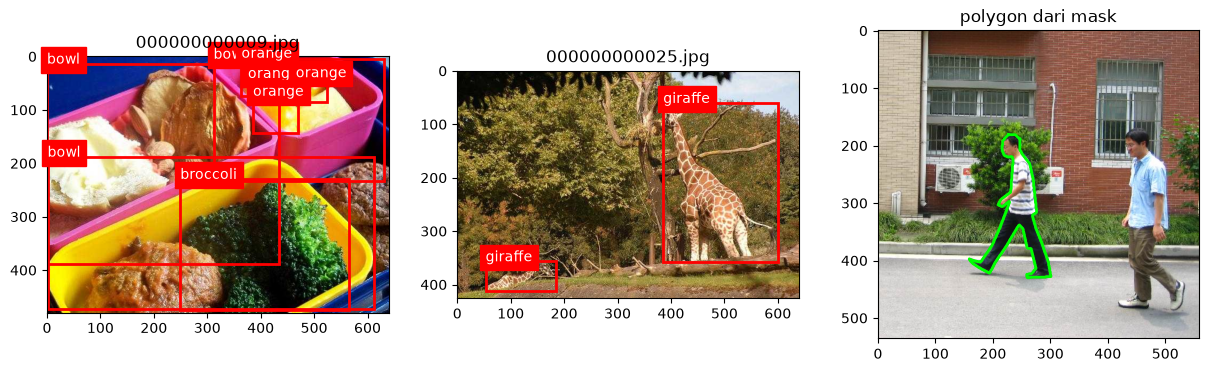

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes[:2], image_names[:2]):
    ax.imshow(Image.open(f"{IMAGE_FOLDER}/{name}"))
    for box in boxes[boxes["image"] == name].itertuples():
        ax.add_patch(Rectangle((box.x1, box.y1), box.x2 - box.x1, box.y2 - box.y1,
                               fill=False, color="red", lw=2))
        ax.text(box.x1, box.y1, CLASS_NAMES[box.class_id], color="white", backgroundcolor="red")
    ax.set_title(name)
axes[2].imshow(Image.open(MASK_IMAGE_FILE))
closed = np.vstack([polygon, polygon[:1]])     # titik pertama diulang supaya garis tertutup
axes[2].plot(closed[:, 0], closed[:, 1], color="lime", lw=2)
axes[2].set_title("polygon dari mask")
fig.savefig("overlay.png", dpi=80)
plt.show()